# Data processing

In [2]:
import pandas as pd

DROP = [
    "rxn_id",
    "ligand_1_cas",
    "ligand_1_smiles",
    "product_1_product_2_ddg_kcal",
]

literature = pd.read_csv("data/HF-Styrene-QM.tsv", sep="\t")

literature["catalyst_key"] = literature["ligand_1_cas"] + "_conformer-" + literature["conformer"].astype(str)

X_lit, y_lit, labels = (
    literature.drop(columns=DROP, axis=1),
    literature["product_1_product_2_ddg_kcal"],
    literature["ligand_1_cas"],
)

In [4]:
import json

import numpy as np
from sklearn.model_selection import GroupShuffleSplit, LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler

run = True

if run:
    logo = LeaveOneGroupOut()

    split = 0
    # First split to separate train+val from test
    for train_val_idx, test_idx in logo.split(X_lit, y_lit, labels):
        # Second split to separate train from val
        val_logo = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
        train_idx, val_idx = next(
            val_logo.split(
                np.array(train_val_idx).reshape(-1, 1),
                groups=labels.iloc[train_val_idx],
            )
        )

        # Save the splits
        train_subset = literature.iloc[train_val_idx].iloc[train_idx].copy()
        val_subset = literature.iloc[train_val_idx].iloc[val_idx].copy()
        test_subset = literature.iloc[test_idx].copy()

        # Save the reaction conditions
        rxn_conds_columns = [
            "temperature_deg_c",
            "ligand_catalyst_ratio",
            "reagent_1_pressure_bar",
            "reagent_2_pressure_bar",
        ]

        dataset = {}

        reaction_conditions = literature[rxn_conds_columns]
        scaler = StandardScaler()
        reaction_conditions = pd.DataFrame(scaler.fit_transform(reaction_conditions), columns=rxn_conds_columns)

        train = {}
        train["rxn_id"] = train_subset["rxn_id"].to_list()
        train["catalyst_key"] = train_subset["catalyst_key"].to_list()
        train["ddG"] = train_subset["product_1_product_2_ddg_kcal"].to_list()
        train["reaction_conditions"] = reaction_conditions.iloc[train_val_idx].iloc[train_idx].values.tolist()

        val = {}
        val["rxn_id"] = val_subset["rxn_id"].to_list()
        val["catalyst_key"] = val_subset["catalyst_key"].to_list()
        val["ddG"] = val_subset["product_1_product_2_ddg_kcal"].to_list()
        val["reaction_conditions"] = reaction_conditions.iloc[train_val_idx].iloc[val_idx].values.tolist()

        test = {}
        test["rxn_id"] = test_subset["rxn_id"].to_list()
        test["catalyst_key"] = test_subset["catalyst_key"].to_list()
        test["ddG"] = test_subset["product_1_product_2_ddg_kcal"].to_list()
        test["reaction_conditions"] = reaction_conditions.iloc[test_idx].values.tolist()

        dataset["train"] = train
        dataset["val"] = val
        dataset["test"] = test

        with open(f"data/jsons/split_{split}.json", "w") as f:
            json.dump(dataset, f, indent=2)

        split += 1

# Results analysis

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

# Lists to store aggregated true values and predictions
test_ddg = []  # True ddG values from test sets across all splits
test_rmses = []  # RMSE for each split's test set
test_predictions = []  # Mean predictions for test sets across all splits
experimental_preds = []  # Predictions for the experimental set from models of each split
experimental_ddg = []  # True ddG values for the experimental set (repeated for each split)

# Iterate through potential split directories (assuming up to 156 splits)
for split in range(156):
    try:
        split_path = Path(f"models/split_{split:03d}")
        if not split_path.exists():
            continue  # Skip if directory doesn't exist

        result_jsons = list(split_path.rglob("results-last.json"))
        if not result_jsons:
            print(f"No results.json found for split {split}")
            continue

        internal_test_ddg = []
        internal_test_rmses = []
        internal_test_predictions = []

        for result_json in result_jsons:
            metrics = result_json.parent / "metrics.csv"
            if metrics.exists():
                df = pd.read_csv(metrics)
                if not df.empty:
                    last_row = df.iloc[-1]
                    last_epoch = int(last_row["epoch"])

            args = result_json.parent / "args.json"
            if args.exists():
                with open(args) as f:
                    args_data = json.load(f)

            val_loss = args_data["val_loss"]

            try:
                with open(result_json) as f:
                    dataset = json.load(f)
            except json.JSONDecodeError:
                print(f"Error decoding JSON in {result_json}")
                continue

            try:
                # Group by reaction ID and calculate mean across conformers
                seed = result_json.parents[2].name
                test = pd.DataFrame(dataset["test"]).groupby("rxn_id").mean(numeric_only=True)

            except (ValueError, KeyError) as e:
                print(f"Error processing test data in {result_json}: {e}")
                continue

            test_rmse = root_mean_squared_error(test["ddG"], test["y_pred"])

            internal_test_ddg.append(test["ddG"])
            internal_test_rmses.append(test_rmse)
            internal_test_predictions.append(test["y_pred"])

        # Aggregate results for this split (average across runs if multiple exist)
        if internal_test_ddg:
            test_ddg.extend(np.mean(internal_test_ddg, axis=0).tolist())
            test_predictions.extend(np.mean(internal_test_predictions, axis=0).tolist())  #
            test_rmses.append(np.mean(internal_test_rmses))
        else:
            print(f"No valid internal test results processed for split {split}")

        # Find and process experimental result files for this split
        exp_jsons = list(split_path.rglob("exp_results-last.json"))
        internal_exp_ddg = []
        internal_exp_preds = []
        for exp_json in exp_jsons:
            seed = exp_json.parents[2].name
            try:
                with open(exp_json) as f:
                    exp_dataset = json.load(f)
            except json.JSONDecodeError:
                print(f"Error decoding JSON in {exp_json}")
                continue

            try:
                # Group experimental results by reaction ID and average across conformers
                exp = pd.DataFrame(exp_dataset).groupby("rxn_id").mean(numeric_only=True)
            except (ValueError, KeyError) as e:
                print(f"Error processing experimental data in {exp_json}: {e}")
                continue

            # Store experimental results for averaging across runs within this split
            internal_exp_ddg.append(exp["ddG"])
            internal_exp_preds.append(exp["y_pred"])

        # Append the averaged experimental predictions and true values for this split
        if internal_exp_ddg:
            experimental_ddg.append(np.mean(internal_exp_ddg, axis=0))
            experimental_preds.append(np.mean(internal_exp_preds, axis=0))
        elif exp_jsons:
            print(f"No valid internal experimental results processed for split {split}")

    except FileNotFoundError:
        print(f"Split directory models/split_{split:03d} not found")
    except Exception as e:
        print(f"An unexpected error occurred processing split {split}: {e}")

# Calculate overall LOCO metrics for the aggregated test set predictions
if test_ddg and test_predictions:
    loco_rmse = root_mean_squared_error(test_ddg, test_predictions)
    loco_mae = mean_absolute_error(test_ddg, test_predictions)
    loco_r2 = r2_score(test_ddg, test_predictions)
    print(f"Total aggregated test predictions: {len(test_ddg)}")
    print(f"LOCO Test RMSE: {loco_rmse:.2f}, MAE: {loco_mae:.2f}, R2: {loco_r2:.2f}")
else:
    print("No test predictions aggregated.")
    loco_rmse, loco_mae, loco_r2 = np.nan, np.nan, np.nan

# Calculate overall metrics for the aggregated experimental set predictions
# Average the predictions across all splits for the final experimental prediction
if experimental_ddg and experimental_preds:
    final_experimental_ddg = experimental_ddg[0].tolist()
    final_experimental_preds = np.mean(experimental_preds, axis=0).tolist()

    print(f"Total aggregated experimental predictions: {len(final_experimental_ddg)}")

    exp_r2 = r2_score(final_experimental_ddg, final_experimental_preds)
    exp_rmse = root_mean_squared_error(final_experimental_ddg, final_experimental_preds)
    exp_mae = mean_absolute_error(final_experimental_ddg, final_experimental_preds)
    print(f"Experimental RMSE: {exp_rmse:.2f}, MAE: {exp_mae:.2f}, R2: {exp_r2:.2f}")
else:
    print("No experimental predictions aggregated.")
    final_experimental_ddg, final_experimental_preds = [], []
    exp_r2, exp_rmse, exp_mae = np.nan, np.nan, np.nan

Total aggregated test predictions: 145
LOCO Test RMSE: 0.41, MAE: 0.31, R2: 0.77
No experimental predictions aggregated.


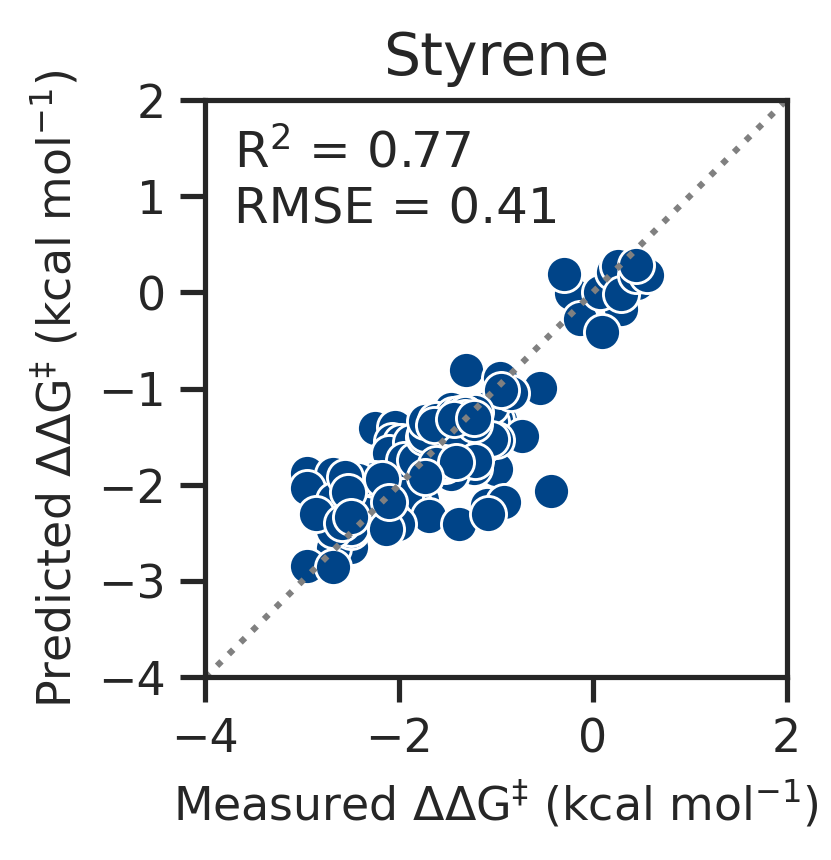

In [2]:
# Define colors and theme
colors = ["#004488", "#DDAA33", "#BB5566", "#000000"]
color = sns.color_palette(colors)
plt.rcParams.update({"figure.figsize": (2.5, 2.5)})
sns.set(rc={"figure.dpi": 300})
sns.set_theme(style="ticks", palette=color)
plt.tight_layout()

ax = sns.scatterplot(
    x=test_ddg,
    y=test_predictions,
    alpha=1,
    s=75,
    legend=False,
)

ax.set(
    xlabel=r"Measured $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
    ylabel=r"Predicted $\Delta\Delta$G$^\ddag$ (kcal mol$^{-1}$)",
)
ax.xaxis.label.set_fontsize(11)
ax.yaxis.label.set_fontsize(11)
ax.set_xlim(-4, 2)
ax.set_ylim(-4, 2)

ax.plot(
    [0, 1],
    [0, 1],
    ":",
    color="grey",
    transform=ax.transAxes,
)
ax.set_title("Styrene", fontsize=14)

ax.text(
    -3.7,
    1.7,
    f"R$^2$ = {loco_r2:0.2f}\nRMSE = {loco_rmse:0.2f}",
    fontsize=12,
    horizontalalignment="left",
    verticalalignment="top",
)

plt.savefig("styrene_loco.svg", format="svg", bbox_inches="tight")